In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("/content/healthcare_data_for_task.csv")

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [7]:
df.describe()

,Age,Billing_Amount
count,1000.000000,1000.000000
mean,51.888000,77117.515720
std,19.256954,41955.242269
min,18.000000,5568.160000
25%,35.750000,40318.785000
50%,52.000000,77293.900000
75%,69.000000,113089.267500
max,85.000000,149921.800000


In [8]:
df.shape

(1000, 10)

In [9]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [10]:
df['Medical_Code']

,Medical_Code
0,HEA004
1,DIA001
2,HEA004
3,HEA004
4,DIA001
...,...
995,DIA001
996,DIA001
997,DIA001
998,DIA001


In [11]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [12]:
df['Medical_Code']=df['Medical_Code'].fillna('Unknown')

In [13]:
df['Admission_Type']=(
    df['Admission_Type']
    .str.strip()
    .str.title()
)


In [14]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent'], dtype=object)

In [15]:
df['Admission_Type'].value_counts()

,count
Admission_Type,
Emergency,381
Elective,368
Urgent,251


In [16]:
df['Date_of_Admission'] = pd.to_datetime(
    df['Date_of_Admission']
)

In [17]:
df['Discharge_Date']=pd.to_datetime(
    df['Discharge_Date']
)


In [18]:
df['Date_of_Admission'].dt.year

,Date_of_Admission
0,2025
1,2025
2,2025
3,2023
4,2024
...,...
995,2023
996,2025
997,2023
998,2023


In [19]:
df['Date_of_Admission'].dt.month

,Date_of_Admission
0,5
1,12
2,11
3,5
4,4
...,...
995,3
996,4
997,5
998,2


In [20]:
df['Date_of_Admission'].dt.day

,Date_of_Admission
0,10
1,31
2,10
3,2
4,11
...,...
995,16
996,17
997,8
998,11


In [21]:
df['Stay_Days'] = (df['Discharge_Date'] - df['Date_of_Admission']).dt.days

In [22]:
df['Billing_Amount'].describe()

,Billing_Amount
count,1000.000000
mean,77117.515720
std,41955.242269
min,5568.160000
25%,40318.785000
50%,77293.900000
75%,113089.267500
max,149921.800000


In [23]:
df.groupby('Medical_Condition')['Age'].mean()

,Age
Medical_Condition,
Arthritis,52.674641
Asthma,49.919598
Diabetes,53.130653
Heart Disease,52.180995
Hypertension,51.395349


In [24]:
pd.crosstab(
    df['Medical_Condition'],
    df['Gender']
)

Gender,Female,Male
Medical_Condition,,
Arthritis,95,114
Asthma,101,98
Diabetes,110,89
Heart Disease,104,117
Hypertension,80,92


<Axes: xlabel='Admission_Type'>

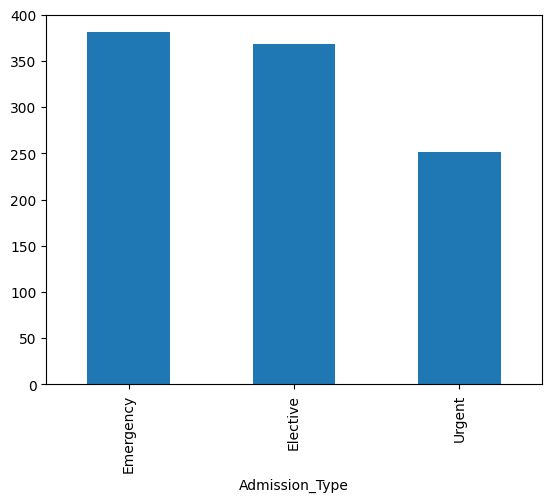

In [25]:
df['Admission_Type'].value_counts().plot(kind='bar')

In [26]:
df[["Medical_Condition", "Admission_Type"]].value_counts().sort_index()


Medical_Condition  Admission_Type
Arthritis          Elective          81
                   Emergency         73
                   Urgent            55
Asthma             Elective          70
                   Emergency         77
                   Urgent            52
Diabetes           Elective          72
                   Emergency         70
                   Urgent            57
Heart Disease      Elective          85
                   Emergency         88
                   Urgent            48
Hypertension       Elective          60
                   Emergency         73
                   Urgent            39
Name: count, dtype: int64

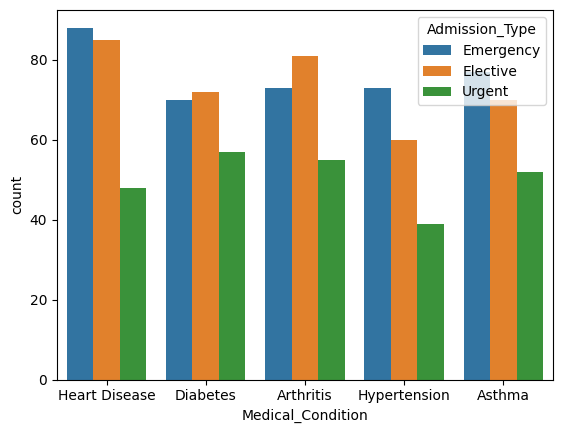

In [27]:
sns.countplot(data=df, x="Medical_Condition", hue="Admission_Type")

plt.show()

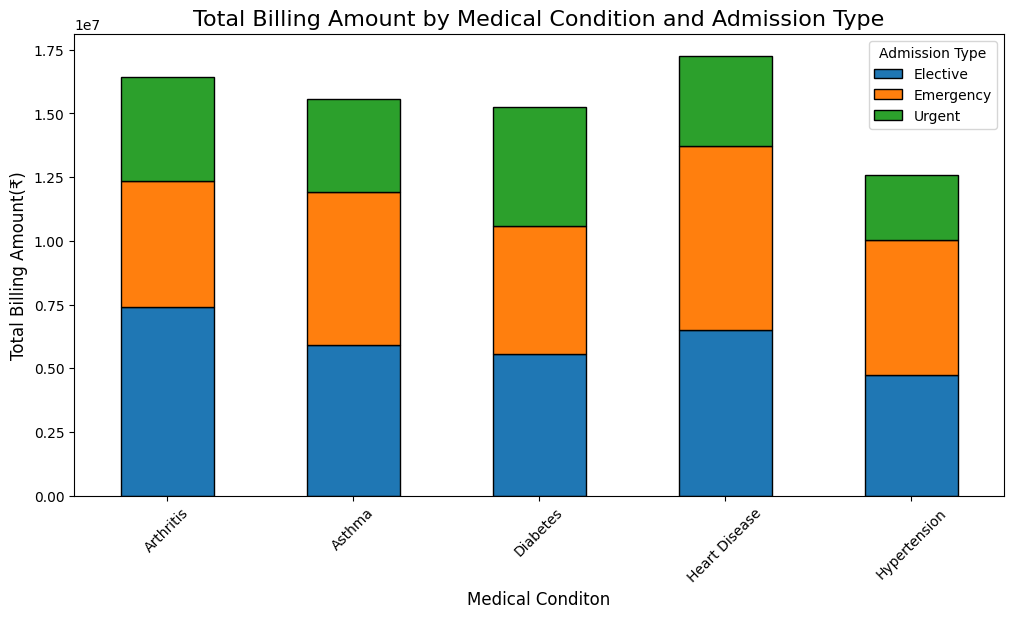

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
billing_summary=(
    df.groupby(['Medical_Condition', 'Admission_Type'])['Billing_Amount']
    .sum()
    .unstack()
)
billing_summary.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Total Billing Amount by Medical Condition and Admission Type',
          fontsize=16)

plt.xlabel('Medical Conditon', fontsize=12)
plt.ylabel('Total Billing Amount(₹)', fontsize=12)

plt.xticks(rotation=45)
plt.legend(title='Admission Type')

plt.show()

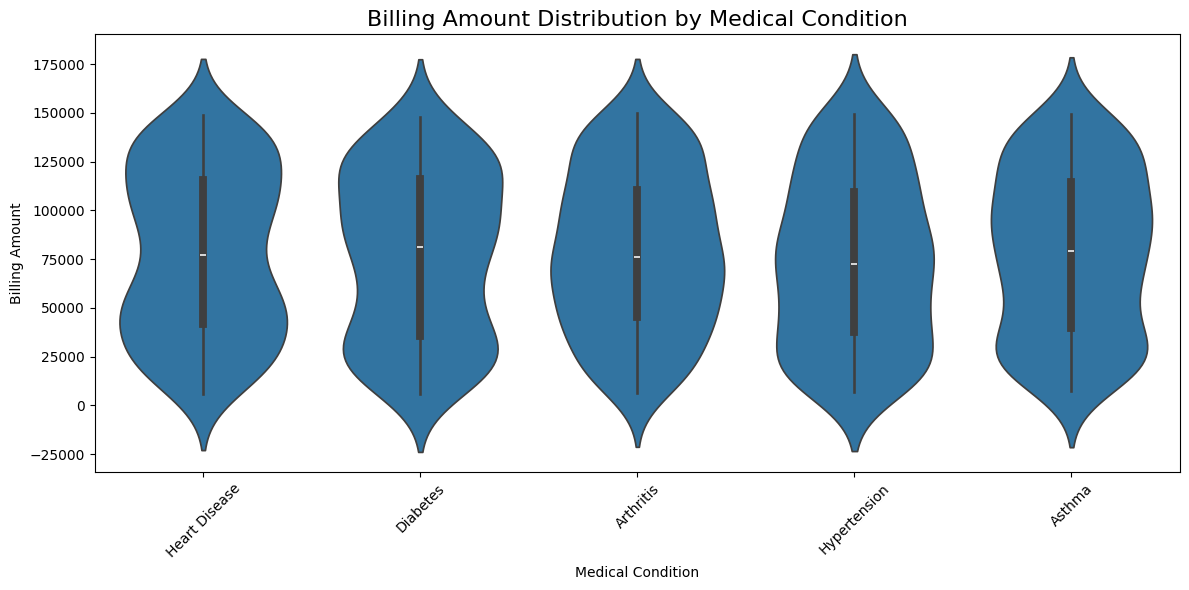

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount'
)

plt.title('Billing Amount Distribution by Medical Condition',
          fontsize=16)

plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [30]:
df

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount,Stay_Days
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31,6
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56,2
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01,17
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71,5
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93,6
...,...,...,...,...,...,...,...,...,...,...,...
995,P0996,24,Female,A+,Diabetes,DIA001,2023-03-16,2023-03-30,Emergency,91315.14,14
996,P0997,63,Female,O+,Diabetes,DIA001,2025-04-17,2025-05-06,Elective,83183.10,19
997,P0998,63,Female,AB+,Diabetes,DIA001,2023-05-08,2023-05-15,Emergency,145478.13,7
998,P0999,33,Male,O-,Diabetes,DIA001,2023-02-11,2023-02-27,Emergency,75210.91,16


In [31]:
df['Date_of_Admission']= pd.to_datetime(
    df['Date_of_Admission']
)

In [32]:
monthly_admissions=(
    df.set_index('Date_of_Admission')
    .resample('ME')
    .size()
)


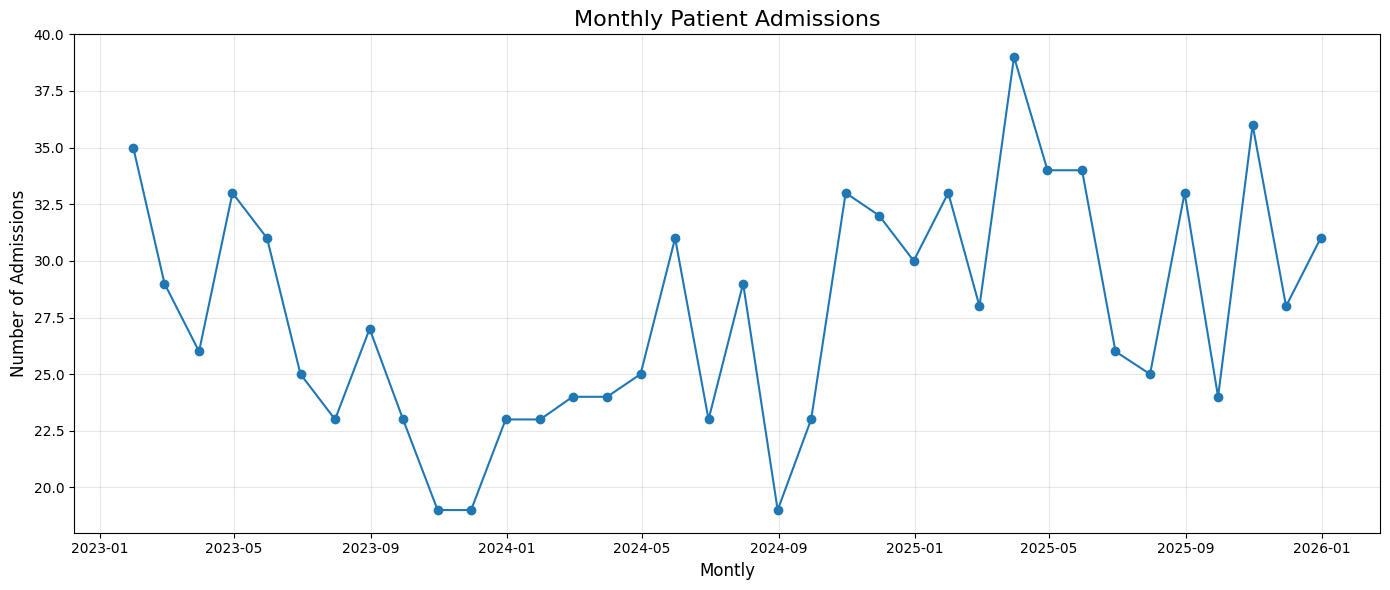

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_admissions.index,
    monthly_admissions.values,
    marker='o'
)

plt.title('Monthly Patient Admissions', fontsize=16)
plt.xlabel('Montly', fontsize=12)
plt.ylabel('Number of Admissions', fontsize=12)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:

numeric_cols = ['Age', 'Stay_Days', 'Billing_Amount']
correlation_matrix = df[numeric_cols].corr()

print(correlation_matrix)

                     Age  Stay_Days  Billing_Amount
Age             1.000000   0.019651        0.009515
Stay_Days       0.019651   1.000000       -0.040583
Billing_Amount  0.009515  -0.040583        1.000000


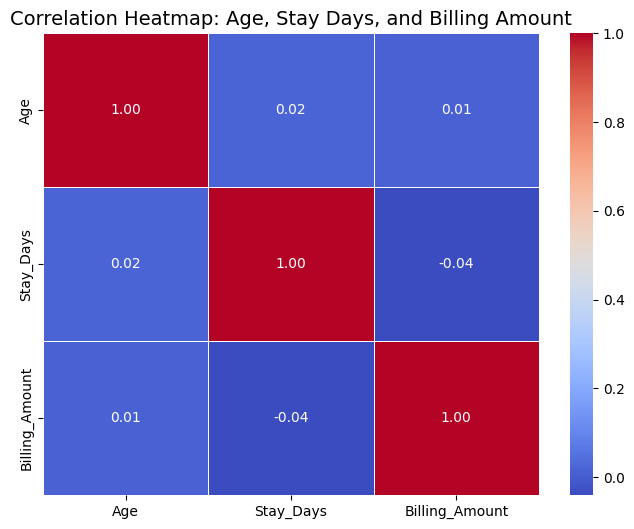

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df[['Age', 'Stay_Days', 'Billing_Amount']].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap: Age, Stay Days, and Billing Amount', fontsize=14)
plt.show()